<a href="https://colab.research.google.com/github/dilekmirac/dip/blob/main/hafta7_g%C3%B6rev4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2
import torch

print(f"OpenCV Versiyonu: {cv2.__version__}")
print(f"CUDA Kullanılabilir mi (PyTorch/GPU): {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"Aktif GPU Modeli: {torch.cuda.get_device_name(0)}")

OpenCV Versiyonu: 4.14.0
CUDA Kullanılabilir mi (PyTorch/GPU): True
Aktif GPU Modeli: Tesla T4


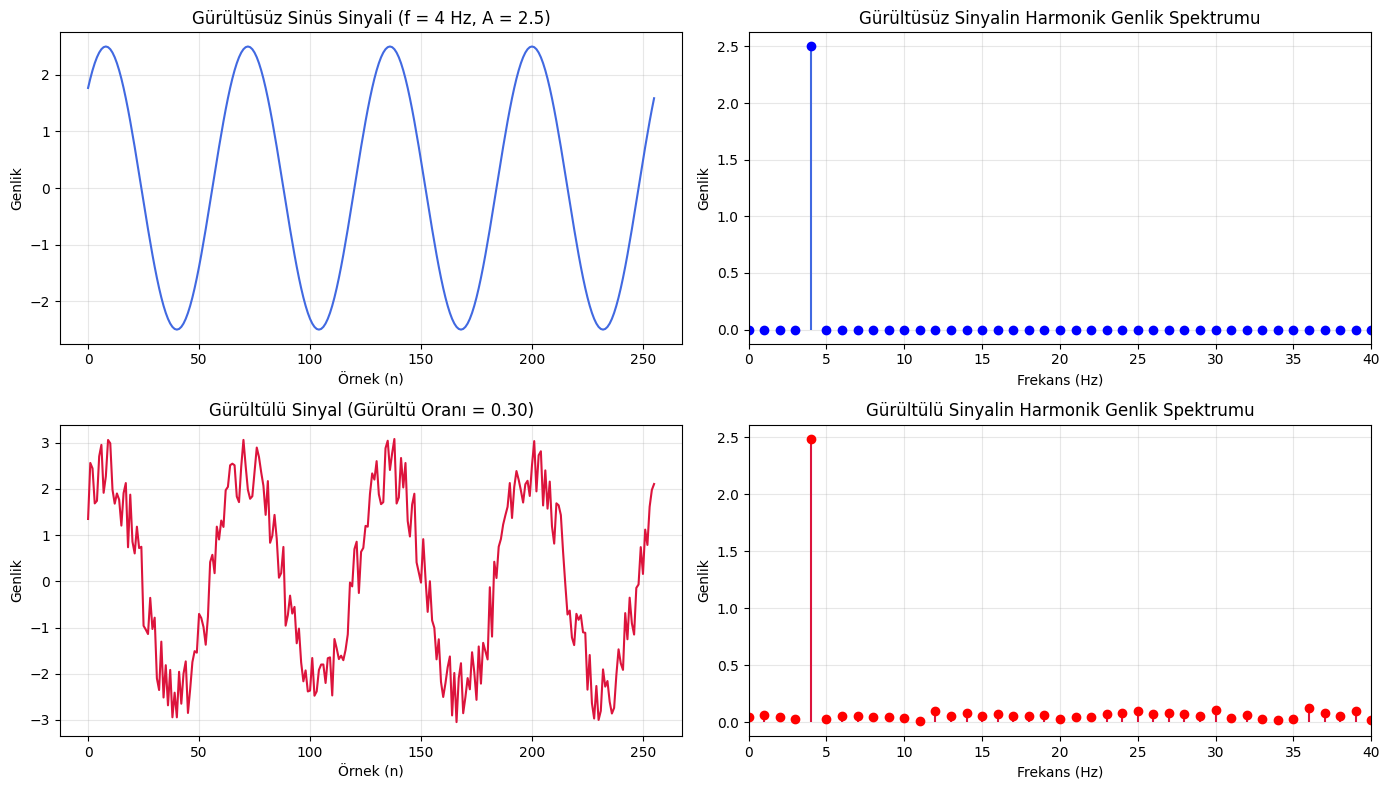

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def doldur_sinus(vec, amplitude=2.5, frequency=4.0, phase=np.pi/4, fs=256.0):
    n = len(vec)
    if n <= 0 or (n & (n - 1)) != 0:
        raise ValueError("Vektör boyutu 2'nin kuvveti olmalıdır.")
    t = np.arange(n, dtype=np.float64) / fs
    vec[:] = amplitude * np.sin(2.0 * np.pi * frequency * t + phase)
    return vec

def gurultu_ekle(vec, noise_ratio):
    if not (0.0 <= noise_ratio <= 1.0):
        raise ValueError("Gürültü oranı [0, 1] aralığında olmalıdır.")
    vec_arr = np.asarray(vec, dtype=np.float64)
    peak_amp = np.max(np.abs(vec_arr))
    if peak_amp == 0:
        peak_amp = 1.0
    noise = np.random.uniform(-1.0, 1.0, size=vec_arr.shape) * (noise_ratio * peak_amp)
    return vec_arr + noise

def dft_1d(vec, fs=256.0):
    """
    2'nin kuvveti uzunluğa sahip 1D vektörün Ayrık Fourier Dönüşümünü (DFT) alır.
    Döndürür:
      harmonics : Karmaşık harmonik vektör X[k] (uzunluğu N)
      magnitude : Normalize edilmiş genlik (harmonik şiddeti) vektörü
      freqs     : Frekans ekseni (Hz)
    """
    x = np.asarray(vec, dtype=np.float64)
    N = len(x)
    if N <= 0 or (N & (N - 1)) != 0:
        raise ValueError("Vektör uzunluğu 2'nin kuvveti olmalıdır (örneğin 128, 256, 512).")

    n = np.arange(N, dtype=np.float64).reshape((N, 1))
    k = np.arange(N, dtype=np.float64).reshape((1, N))

    dft_matrix = np.exp(-1j * 2.0 * np.pi * (n @ k) / N)
    harmonics = x @ dft_matrix

    magnitude = (np.abs(harmonics) / N) * 2.0
    magnitude[0] = np.abs(harmonics[0]) / N

    freqs = np.arange(N, dtype=np.float64) * (fs / N)
    return harmonics, magnitude, freqs

N = 256
clean_vec = np.zeros(N, dtype=np.float64)
doldur_sinus(clean_vec, amplitude=2.5, frequency=4.0, phase=np.pi/4, fs=N)

noisy_vec = gurultu_ekle(clean_vec, noise_ratio=0.30)

harm_clean, mag_clean, freqs = dft_1d(clean_vec, fs=N)
harm_noisy, mag_noisy, _ = dft_1d(noisy_vec, fs=N)

half_N = N // 2

plt.figure(figsize=(14, 8))

plt.subplot(2, 2, 1)
plt.plot(clean_vec, color='royalblue')
plt.title('Gürültüsüz Sinüs Sinyali (f = 4 Hz, A = 2.5)')
plt.xlabel('Örnek (n)')
plt.ylabel('Genlik')
plt.grid(True, alpha=0.3)

plt.subplot(2, 2, 2)
plt.stem(freqs[:half_N], mag_clean[:half_N], linefmt='royalblue', markerfmt='bo', basefmt=" ")
plt.title('Gürültüsüz Sinyalin Harmonik Genlik Spektrumu')
plt.xlabel('Frekans (Hz)')
plt.ylabel('Genlik')
plt.xlim(0, 40)
plt.grid(True, alpha=0.3)

plt.subplot(2, 2, 3)
plt.plot(noisy_vec, color='crimson')
plt.title('Gürültülü Sinyal (Gürültü Oranı = 0.30)')
plt.xlabel('Örnek (n)')
plt.ylabel('Genlik')
plt.grid(True, alpha=0.3)

plt.subplot(2, 2, 4)
plt.stem(freqs[:half_N], mag_noisy[:half_N], linefmt='crimson', markerfmt='ro', basefmt=" ")
plt.title('Gürültülü Sinyalin Harmonik Genlik Spektrumu')
plt.xlabel('Frekans (Hz)')
plt.ylabel('Genlik')
plt.xlim(0, 40)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()